# **Ski Pass Price Prediction**

## **Project Scope**

### **Goal**

* Predict the cost of a 1-day ski pass for an adult.

### **Data Source**

* [Ski Resorts dataset from Maven Analytics](https://mavenanalytics.io/data-playground/ski-resorts), which has data on roughly 500 ski resorts around the world, such as location, prices, slopes, lifts, and seasons.

* This project uses `resorts.csv`. The companion snow-cover table is not used.

### **Techniques**

* Supervised learning using regression techniques (linear regression and regularized regression models such as Ridge and Lasso).

### **Objectives**

* Identify the top predictors that influence ski resort pricing.

* Explore relationships between resort features and price.

* Build a model to predict ski pass prices.

### **Impact**

* Helping ski resorts understand what affects ski pass prices so they can decide how much to charge and compare themselves to other resorts.

## **1. Load and Inspect Data**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import scipy.stats as stats
from sklearn.model_selection import KFold
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score as r2
from sklearn.metrics import mean_absolute_error as mae
from sklearn.metrics import root_mean_squared_error as rmse
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV

resorts_df = pd.read_csv('resorts.csv', index_col = "ID", encoding='latin-1')

resorts_df.head()

,Resort,Latitude,Longitude,Country,Continent,Price,Season,Highest point,Lowest point,Beginner slopes,...,Snow cannons,Surface lifts,Chair lifts,Gondola lifts,Total lifts,Lift capacity,Child friendly,Snowparks,Nightskiing,Summer skiing
ID,,,,,,,,,,,,,,,,,,,,,
1,Hemsedal,60.928244,8.383487,Norway,Europe,46,November - May,1450,620,29,...,325,15,6,0,21,22921,Yes,Yes,Yes,No
2,Geilosiden Geilo,60.534526,8.206372,Norway,Europe,44,November - April,1178,800,18,...,100,18,6,0,24,14225,Yes,Yes,Yes,No
3,Golm,47.057810,9.828167,Austria,Europe,48,December - April,2110,650,13,...,123,4,4,3,11,16240,Yes,No,No,No
4,Red Mountain Resort-Rossland,49.105520,-117.846280,Canada,North America,60,December - April,2075,1185,20,...,0,2,5,1,8,9200,Yes,Yes,Yes,No
5,Hafjell,61.230369,10.529014,Norway,Europe,45,November - April,1030,195,33,...,150,14,3,1,18,21060,Yes,Yes,Yes,No


### **Notes**

* The `ID` column was set as the index, so each row has a clear label instead of default numbering to make the data easier to understand and work with.

* A different encoding (`latin-1`) was used because the dataset has special characters, such as accented letters and dashes that could not be read with default UTF-8 encoding.

In [2]:
resorts_df.shape

(499, 24)

In [3]:
resorts_df.describe()

,Latitude,Longitude,Price,Highest point,Lowest point,Beginner slopes,Intermediate slopes,Difficult slopes,Total slopes,Longest run,Snow cannons,Surface lifts,Chair lifts,Gondola lifts,Total lifts,Lift capacity
count,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000,499.000000
mean,43.205684,-6.006784,48.721443,2160.589178,1200.631263,31.819639,37.921844,16.164329,85.905812,3.545090,179.136273,11.282565,9.721443,3.258517,24.262525,31650.961924
std,15.975790,59.990459,21.718733,774.339805,596.142294,47.401764,44.358524,20.115855,100.874157,3.947887,372.321111,13.365360,11.461502,5.867967,27.672736,40781.986019
min,-45.054960,-149.740657,0.000000,163.000000,36.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,43.672650,1.380975,36.000000,1594.000000,800.000000,10.000000,12.000000,3.000000,30.000000,0.000000,0.000000,3.000000,3.000000,0.000000,10.000000,11645.000000
50%,46.347316,8.206372,45.000000,2175.000000,1121.000000,18.000000,25.000000,9.000000,55.000000,3.000000,15.000000,7.000000,6.000000,1.000000,15.000000,18510.000000
75%,47.327089,12.429237,54.000000,2700.000000,1500.000000,30.000000,45.000000,21.000000,100.000000,6.000000,180.000000,14.000000,11.500000,4.000000,26.000000,32829.000000
max,67.784406,176.876668,141.000000,3914.000000,3286.000000,312.000000,239.000000,126.000000,600.000000,16.000000,2383.000000,89.000000,74.000000,40.000000,174.000000,252280.000000


### **Notes**

* The minimum value for `Price` is 0, which doesn't make sense since it is unlikely that a 1-day adult ski pass would be free. These rows will be looked at more closely to see if they have missing or incorrect price values.

* The median `Price` is 45, while the highest price is 141, which shows that most resorts charge lower prices for their ski passes compared to the most expensive resorts.

* `Total slopes`, `Snow cannons`, `Total lifts`, and `Lift capacity` have very large ranges, suggesting that some resorts are much bigger than others.

In [4]:
resorts_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 499 entries, 1 to 499
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Resort               499 non-null    object 
 1   Latitude             499 non-null    float64
 2   Longitude            499 non-null    float64
 3   Country              499 non-null    object 
 4   Continent            499 non-null    object 
 5   Price                499 non-null    int64  
 6   Season               499 non-null    object 
 7   Highest point        499 non-null    int64  
 8   Lowest point         499 non-null    int64  
 9   Beginner slopes      499 non-null    int64  
 10  Intermediate slopes  499 non-null    int64  
 11  Difficult slopes     499 non-null    int64  
 12  Total slopes         499 non-null    int64  
 13  Longest run          499 non-null    int64  
 14  Snow cannons         499 non-null    int64  
 15  Surface lifts        499 non-null    int64  


### **Notes**

* All of the columns have 499 non-null values, which means that there are not any missing values in the dataset.

* The data types are correct.

## **2. Data Cleaning**

In [5]:
resorts_df[resorts_df["Price"] == 0]

,Resort,Latitude,Longitude,Country,Continent,Price,Season,Highest point,Lowest point,Beginner slopes,...,Snow cannons,Surface lifts,Chair lifts,Gondola lifts,Total lifts,Lift capacity,Child friendly,Snowparks,Nightskiing,Summer skiing
ID,,,,,,,,,,,,,,,,,,,,,
196,Perisher,-36.396167,148.408582,Australia,Oceania,0,June - October,1605,1125,22,...,271,34,14,1,49,46975,Yes,Yes,Yes,Yes
235,Yellowstone Club,45.668198,-111.067446,United States,North America,0,November - April,3005,2182,30,...,0,4,11,0,15,14886,Yes,No,No,No
335,Pragelato,45.016217,6.942453,Italy,Europe,0,December - April,2700,1335,14,...,0,4,1,0,5,3660,Yes,No,No,No
349,Uludag?-Bursa,40.070529,29.222010,Turkey,Asia,0,Unknown,1767,395,10,...,0,8,6,2,16,19637,Yes,Yes,No,No
369,Palando?ken-Ejder 3200 World Ski Center-,39.543016,42.915247,Turkey,Asia,0,November - April,3176,2200,19,...,0,3,11,2,16,15390,Yes,Yes,Yes,No
387,High1 Resort,37.207294,128.824816,South Korea,Asia,0,December - April,1367,690,4,...,0,1,6,4,11,26685,Yes,No,No,No
390,Alpika Service,43.667196,40.246821,Russia,Europe,0,December - April,2228,535,10,...,0,1,1,7,9,18120,Yes,No,No,No
475,Sun Mountain-Yabuli,44.929398,128.604393,China,Asia,0,November - April,1375,457,3,...,0,4,2,0,6,13776,Yes,No,No,No
495,Puigmal,42.395007,2.108883,France,Europe,0,Unknown,2700,1830,9,...,0,11,2,0,13,11865,Yes,No,No,No


### **Notes**

* 9 resorts have a `Price` of 0 and are located in different countries, which means this is likely a data issue and not just a problem in one location.

* A few small issues were found, such as an "Unknown" in the `Season` column, and unusual characters (such as `?` or `-`) in some of the resort names.

* These rows will be removed since ski passes are unlikely to be free, and the true price is not known.

In [6]:
resorts_df = resorts_df[resorts_df["Price"] != 0]

resorts_df.shape

(490, 24)

In [7]:
resorts_df.duplicated().sum()

np.int64(0)

## **3. Exploratory Data Analysis (EDA)**

### **Target Analysis**

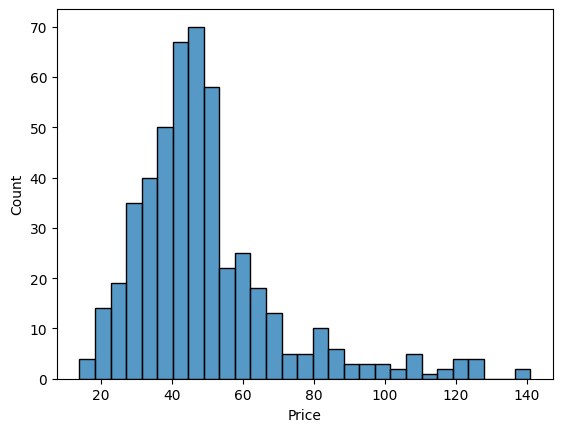

In [8]:
sns.histplot(resorts_df["Price"]);

### **Notes**

* Most ski resort passes are roughly between €30 and €60.

* The distribution is right-skewed, which means that most ski resorts charge lower prices, while a small number charge higher prices.

* The most common price range is roughly between €40 and €50.

* There is a secondary bump around the €80 price range, which may suggest that another feature, such as resort size, location, or amenities, is influencing higher prices for some resorts.

* There are a few high-price outliers greater than €100, with the highest being €141, which means a few ski resorts charge much higher prices compared to the rest.

### **Feature Relationships**

#### **Correlation Matrix**

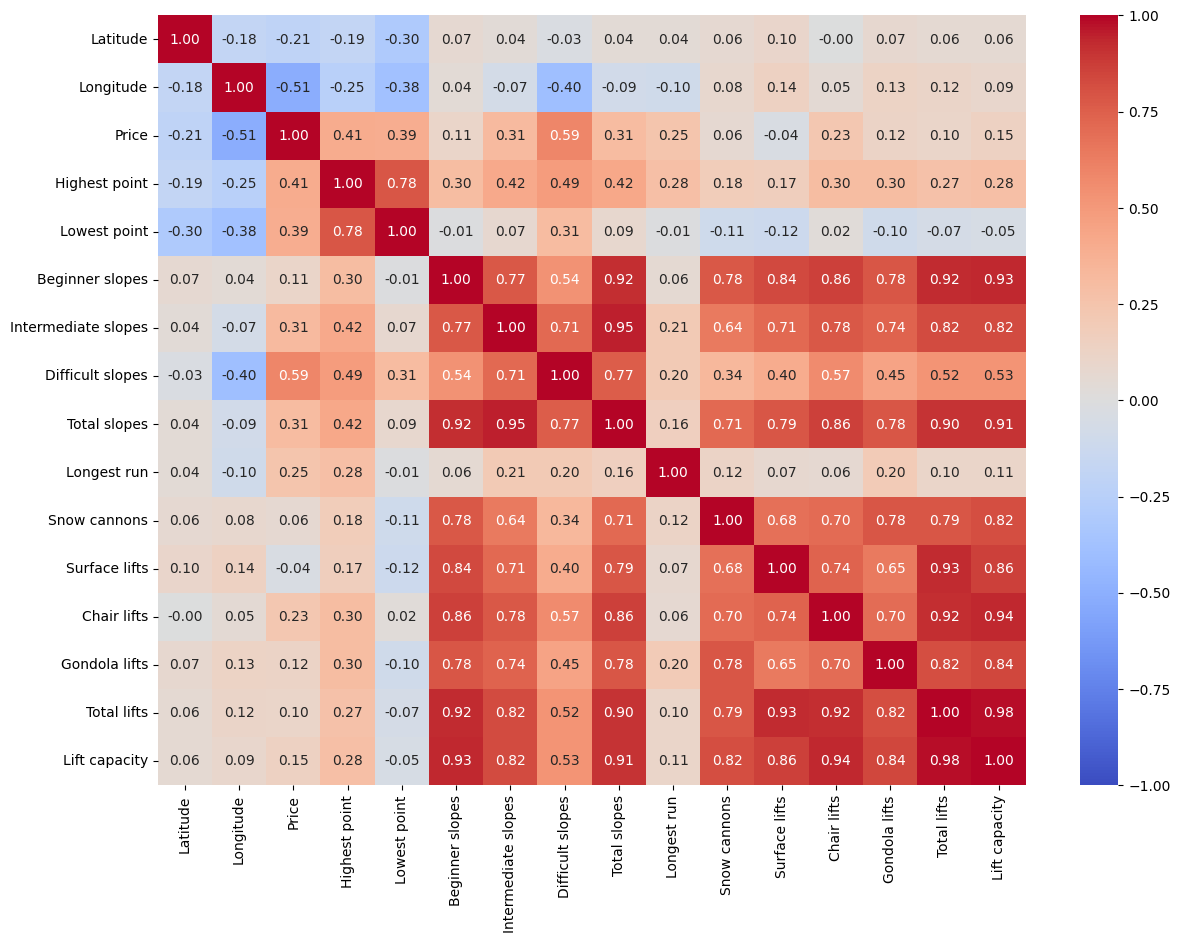

In [9]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    resorts_df.corr(numeric_only=True),
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    annot=True ,
    fmt=".2f"
);

### **Notes**

* `Price` has a moderate positive relationship with  `Difficult slopes` (≈ 0.59), suggesting that resorts that have advanced terrain tend to charge more for ski passes.

* `Price` shows a moderate relationship with `Highest point` (≈ 0.41), though it is not very strong, suggesting that elevation may affect `Price.`

* `Price` has a weak positive relationship with `Lowest point` (≈ 0.39), though it is close to moderate.

* Price has weak positive relationships with `Intermediate slopes` (≈ 0.31) and `Total slopes` (≈ 0.31), suggesting these features have a smaller influence on pricing.

* Many of the variables related to slope and lift are highly correlated with one another, with `Total lifts` and `Lift capacity` being especially strongly correlated, which means they are repeating the same information.

* `Longitude` shows a moderate negative relationship with `Price`, suggesting that where the resort is located may impact `Price.`

#### **Pairplot**

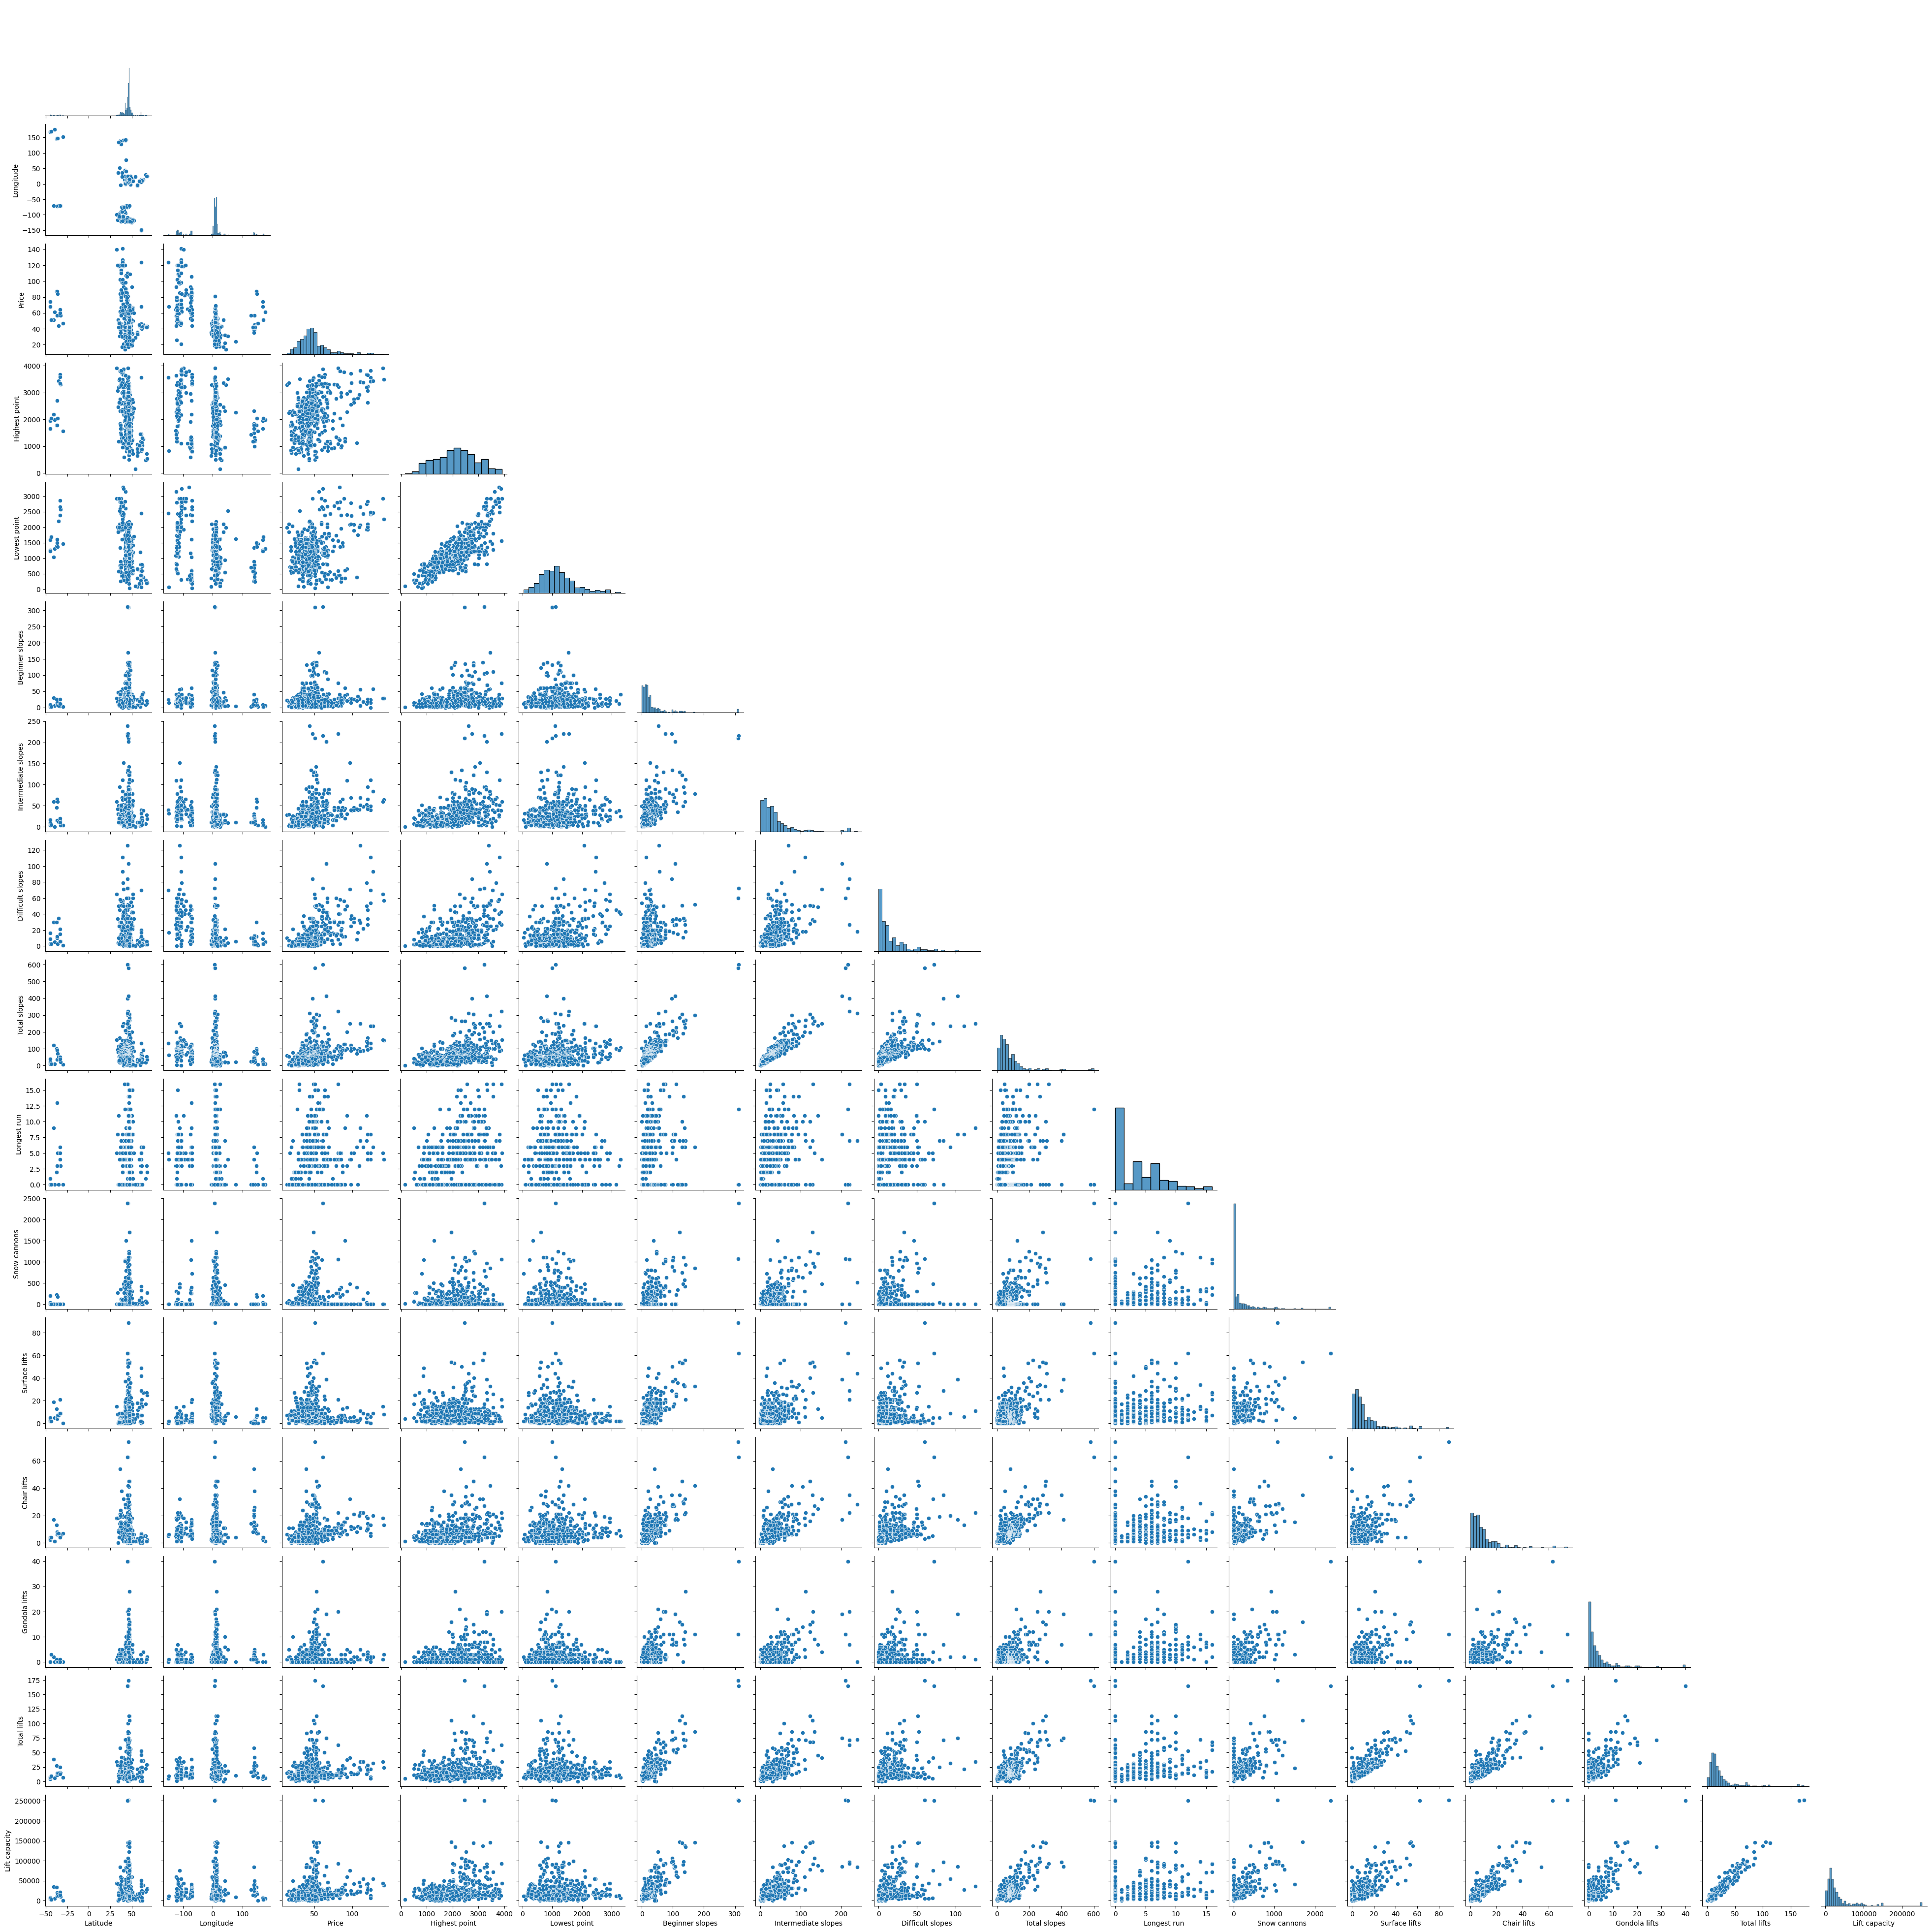

In [10]:
sns.pairplot(resorts_df.select_dtypes("number"), corner=True);

### **Notes**

* `Price` increases as the number of difficult slopes increases, though the relationship is not perfectly linear.

* `Highest point` and `Lowest point` have a strong relationship with one another, which means they contain overlapping elevation information.

* Features related to slope, such as `Beginner slopes`, `Intermediate slopes`, `Difficult slopes`, and `Total slopes`, are strongly related, signaling that there is multicollinearity between these variables. Similar relationships were observed in the correlation matrix.

* Lift-related features such as `Surface lifts`, `Chair lifts`, `Gondola lifts`, `Total lifts`, and `Lift capacity` also have strong positive relationships, which shows that larger resorts tend to have more lift infrastructure. These relationships are consistent with the findings from the correlation matrix.

* `Price`, `Difficult slopes`, and `Lift capacity`, and several other variables related to the size of a resort are right-skewed, and there are a few resorts that have much higher values than the rest, which makes them stand out.

* There are noticeable outliers in several variables, especially `Lift capacity`, `Snow cannons,` and those that are slope-related, which could affect the analysis and modeling.

* Many of the relationships are somewhat scattered rather than perfectly linear, suggesting that ski pass prices are influenced by multiple resort characteristics rather than a single variable.

#### **Lmplot**

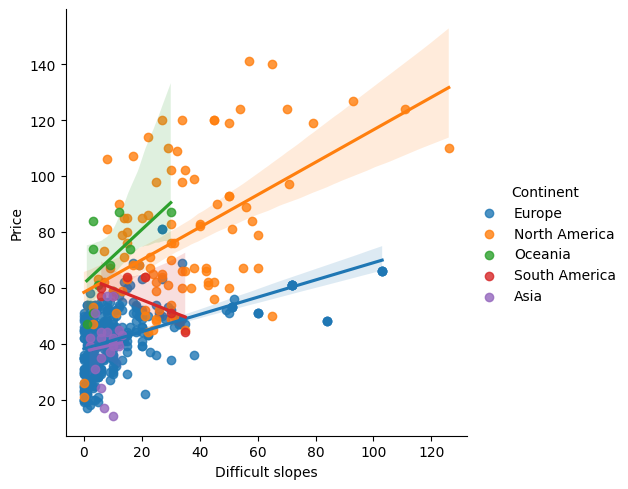

In [11]:
sns.lmplot(
    data=resorts_df,
    x="Difficult slopes",
    y="Price",
    hue="Continent"
);

### **Notes**

* Resorts that have more difficult slopes tend to charge higher ski pass prices, though the strength of the relationships differs across continents.

* North American resorts have the strongest positive relationship between `Difficult slopes` and `Price`, which suggests that resorts that have advanced terrain tend to charge substantially higher prices.

* European resorts have a positive relationship between `Difficult slopes` and `Price`, although the increase in price is smaller compared to North America.

* Asia and South America tend to cluster around lower prices and fewer difficult slopes, while North American resorts are generally more spread out and include many of the highest-priced resorts.

* There is greater price variation at higher numbers of difficult slopes, especially in North America, suggesting that pricing is more spread out among larger or more advanced resorts.

* Overall, the plot suggests that resort difficulty and geographic region impact ski pass pricing.

#### **Categorical Feature Frequency**

In [12]:
def value_counter(dataframe):
  for col in dataframe.select_dtypes(["object"]).columns:
    print(dataframe[col].value_counts(), "\n")

value_counter(resorts_df)

Resort
Le Massif                        1
Hemsedal                         1
Geilosiden Geilo                 1
Golm                             1
Red Mountain Resort-Rossland     1
                                ..
Zermatt - Matterhorn             1
Brauneck Lenggries ?Wegscheid    1
Panorama                         1
Sun Peaks                        1
Fernie                           1
Name: count, Length: 490, dtype: int64 

Country
Austria                   89
France                    80
United States             77
Switzerland               59
Italy                     43
Germany                   22
Canada                    20
Japan                     14
Norway                    10
Spain                      8
Sweden                     6
Chile                      5
New Zealand                5
Andorra                    5
Slovakia                   5
Australia                  4
United Kingdom             4
Bulgaria                   4
Slovenia                   4
Russia  

### **Notes**

* All of the values in `Resort` are unique since it is an identifier, which does not make it a useful predictive feature.

* Most resorts are located in Europe, followed by North America, while the other continents have much fewer resorts, making `Continent` somewhat imbalanced.

* Since there are many categories in `Country`, with some countries appearing only a few times, grouping less common categories will be useful.

* `Season` has inconsistent formatting and rare values, so it will need to be cleaned or grouped; most resorts operate in winter, with the most common ranges being December-April and November-April.

* Almost all resorts are `Child-friendly`, which means it is not a useful predictive feature due to little variation.

* Most resorts have `Snowparks`, though a good portion do not; this makes it a useful feature since it has some variation.

* `Nightskiing` has a fairly even split between Yes and No values, making it a useful feature due to its variation.

* Very few resorts offer `Summer skiing`, which makes this feature highly imbalanced.




#### **Categorical Features vs Price (Barplots)**

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 150 (\x96) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 146 (\x92) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


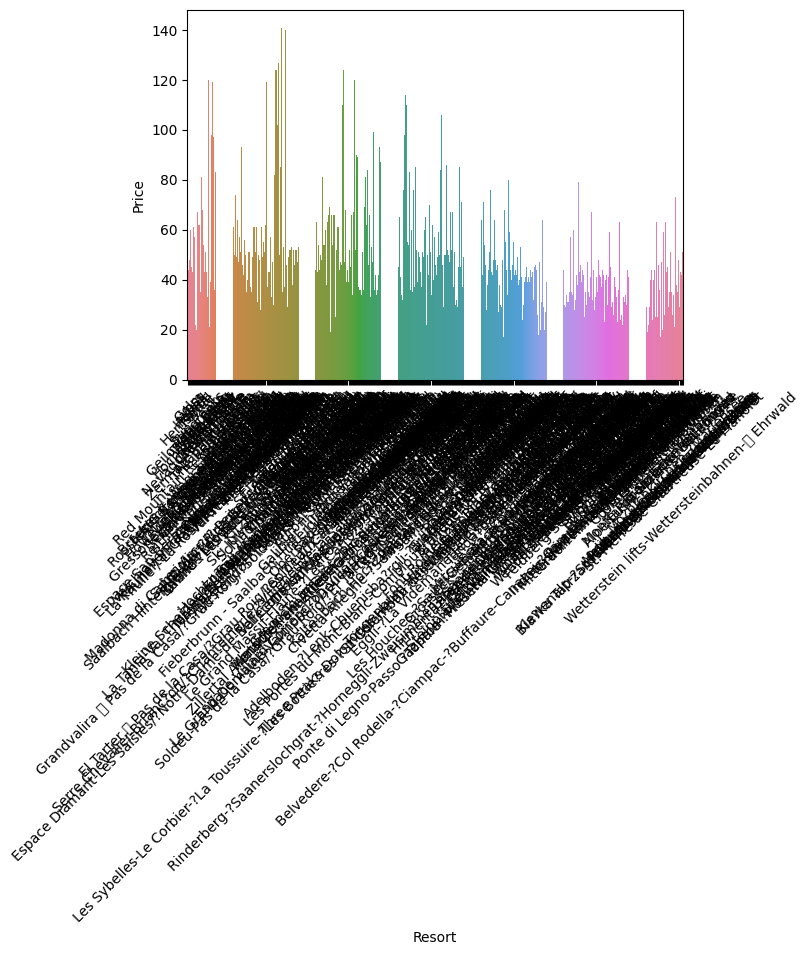

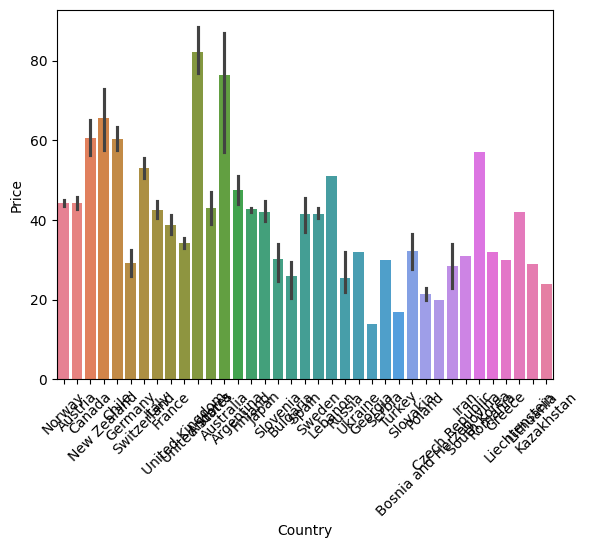

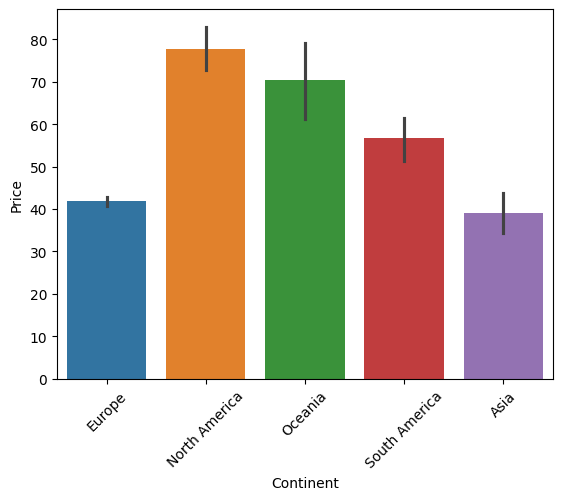

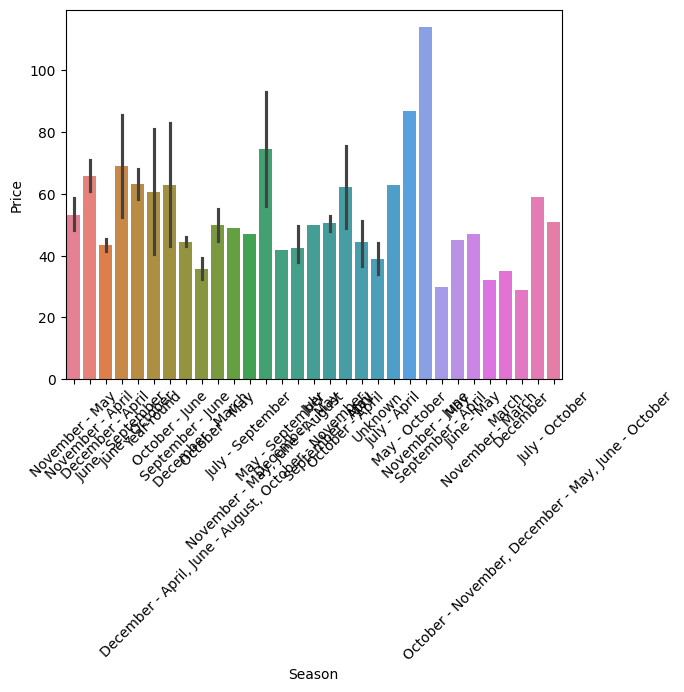

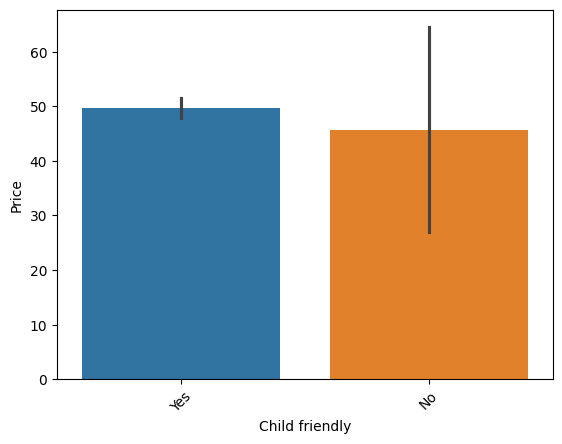

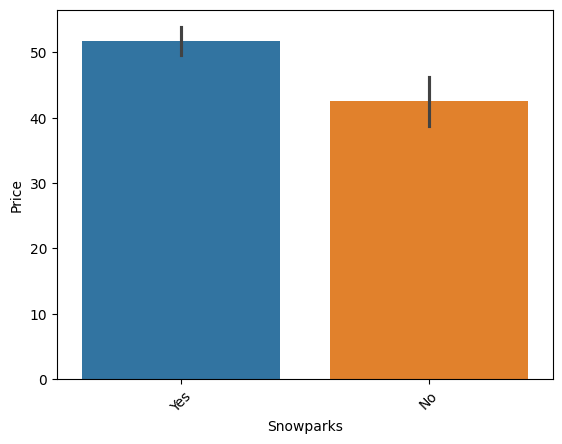

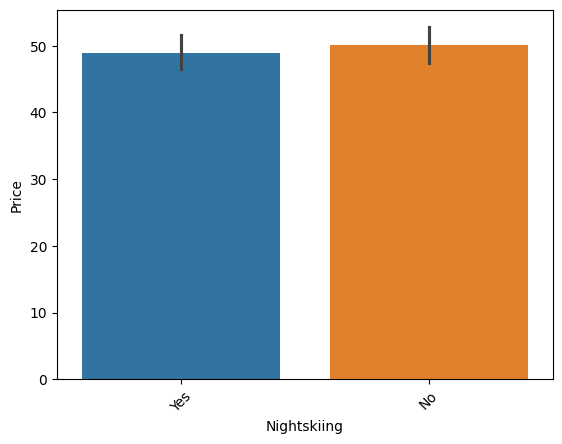

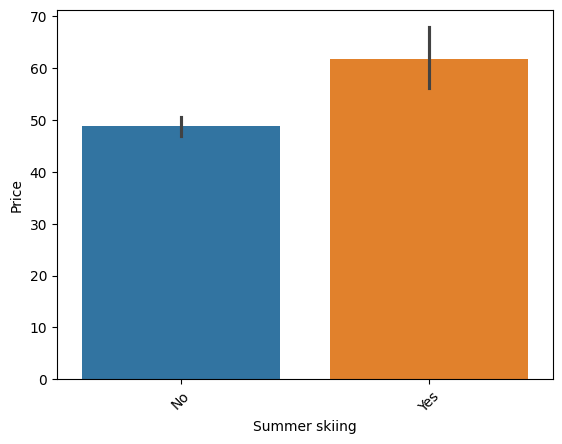

In [13]:
def cat_plotter(data, target):
  for col in data.select_dtypes(["object"]).columns:
    sns.barplot(data=data, x=col, y=target, hue=col)
    plt.xticks(rotation=45)
    plt.show()

cat_plotter(resorts_df, "Price")

### **Notes**

* `Resort` does not have a strong relationship with price, which is not surprising since each resort appears only once and serves as an identifier.

* Average ski pass prices vary by country and continent, which suggests that where a resort is located affects how much it charges.

* Resorts in North America have the highest average ski pass prices, while Resorts located in Asia have the lowest.

* `Season` shows differences in average ski prices across categories, but it has too many categories and inconsistent formatting, making it difficult to interpret. This highlights the need to clean and group this variable before modeling.

* Resorts that are child-friendly and non-child-friendly have similar average ski pass prices in addition to almost all resorts being child-friendly, which means that this feature is unlikely to add much value when it comes to predicting price.

* Resorts with snowparks charge higher average ski pass prices than resorts that do not, which makes this feature useful for modeling.

* Resorts that offer and do not offer nightskiing have similar average ski pass prices, which means that it is unlikely that nightskiing strongly influences pricing.

* Resorts that offer summer skiing have higher average ski pass prices than those that don't, which suggests summer skiing is more common at higher-priced resorts.

## **4. Simple Linear Regression**

### **Simple Model Results**

In [14]:
X = sm.add_constant(resorts_df["Difficult slopes"])
y = resorts_df["Price"]

simple_model = sm.OLS(y, X).fit()

print(f"MAE: {mae(y, simple_model.predict())}")
print(f"RMSE: {rmse(y, simple_model.predict())}")

simple_model.summary()

MAE: 12.05822502607177
RMSE: 16.859595023157446


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.347
Model:                            OLS   Adj. R-squared:                  0.345
Method:                 Least Squares   F-statistic:                     258.8
Date:                Wed, 19 Aug 2026   Prob (F-statistic):           4.96e-47
Time:                        07:21:10   Log-Likelihood:                -2079.5
No. Observations:                 490   AIC:                             4163.
Df Residuals:                     488   BIC:                             4171.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               39.7481      0.979     40.595      0.000      37.824      41.672
Difficult slopes     0.6064      0.038     16.088      0.000       0.532       0.680
==============================================================================
Omnibus:                      109.296   Durbin-Watson:                   1.570
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              244.838
Skew:                           1.161   Prob(JB):                     6.82e-54
Kurtosis:                       5.569   Cond. No.                         33.3
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

### **Notes**

* The model explains about 34.7% of the variation in ski pass prices, which shows that 'Difficult slopes' is a useful predictor, but it does not capture all of the factors that influence price.

* 'Difficult slopes' has a positive relationship with 'Price'. For each additional difficult slope, the predicted ski pass price increases by about €0.61 on average.

* The p-value is less than 0.05, which shows that the relationship between 'Difficult slopes' and 'Price' is statistically significant.

* The baseline model is a useful starting point, although additional features will likely improve the prediction accuracy.

### **Residual Analysis**

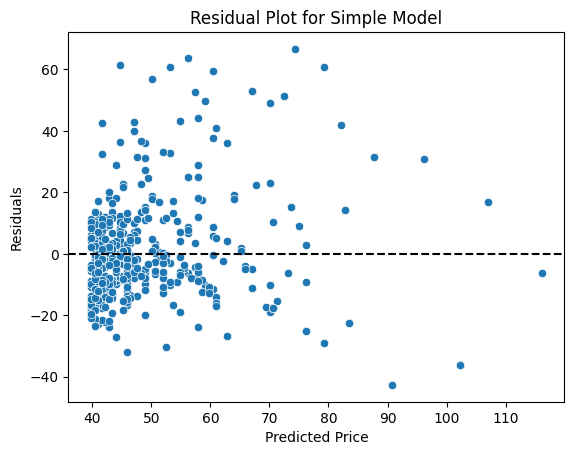

In [15]:
sns.scatterplot(x=simple_model.predict(), y=simple_model.resid)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot for Simple Model");

### **Notes**

* Most of the prediction errors are close to 0, which shows that many predicted ski pass prices are similar to the actual prices.

* The model has a harder time predicting the prices of more expensive resorts, as shown by the larger residuals.

* There are a few noticeable outliers, which show that the model does not predict the prices of some resorts as well as others.

* Overall, the model provides a useful starting point, but using only `Difficult slopes` is not enough to fully explain ski pass prices.


## **5. Multiple Linear Regression**

### **Model 1**

In [16]:
X = sm.add_constant(resorts_df[["Difficult slopes", "Highest point"]])
y = resorts_df["Price"]

model_1 = sm.OLS(y, X).fit()

print(f"MAE: {mae(y, model_1.predict())}")
print(f"RMSE: {rmse(y, model_1.predict())}")

model_1.summary()

MAE: 11.918755413627895
RMSE: 16.629234544465458


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.364
Model:                            OLS   Adj. R-squared:                  0.362
Method:                 Least Squares   F-statistic:                     139.5
Date:                Wed, 19 Aug 2026   Prob (F-statistic):           1.24e-48
Time:                        07:21:11   Log-Likelihood:                -2072.7
No. Observations:                 490   AIC:                             4151.
Df Residuals:                     487   BIC:                             4164.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               32.1246      2.283     14.071      0.000      27.639      36.610
Difficult slopes     0.5290      0.043     12.379      0.000       0.445       0.613
Highest point        0.0041      0.001      3.686      0.000       0.002       0.006
==============================================================================
Omnibus:                      104.486   Durbin-Watson:                   1.578
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              220.230
Skew:                           1.139   Prob(JB):                     1.51e-48
Kurtosis:                       5.366   Cond. No.                     6.95e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.95e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### **Model 2**

In [17]:
X = sm.add_constant(
    resorts_df[[
        "Difficult slopes",
        "Highest point",
        "Longest run"
    ]]
)

y = resorts_df["Price"]

model_2 = sm.OLS(y, X).fit()

print(f"MAE: {mae(y, model_2.predict())}")
print(f"RMSE: {rmse(y, model_2.predict())}")

model_2.summary()

MAE: 11.642343620402006
RMSE: 16.49073045694671


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.375
Model:                            OLS   Adj. R-squared:                  0.371
Method:                 Least Squares   F-statistic:                     97.14
Date:                Wed, 19 Aug 2026   Prob (F-statistic):           2.88e-49
Time:                        07:21:11   Log-Likelihood:                -2068.7
No. Observations:                 490   AIC:                             4145.
Df Residuals:                     486   BIC:                             4162.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               31.7489      2.270     13.985      0.000      27.288      36.209
Difficult slopes     0.5195      0.043     12.209      0.000       0.436       0.603
Highest point        0.0034      0.001      3.012      0.003       0.001       0.006
Longest run          0.5662      0.198      2.863      0.004       0.178       0.955
==============================================================================
Omnibus:                      115.362   Durbin-Watson:                   1.597
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              256.701
Skew:                           1.228   Prob(JB):                     1.81e-56
Kurtosis:                       5.557   Cond. No.                     6.96e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 6.96e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### **Model 3**

In [18]:
X = sm.add_constant(
    resorts_df[[
        "Difficult slopes",
        "Highest point",
        "Longest run",
        "Snow cannons"
    ]]
)

y = resorts_df["Price"]

model_3 = sm.OLS(y, X).fit()

print(f"MAE: {mae(y, model_3.predict())}")
print(f"RMSE: {rmse(y, model_3.predict())}")

model_3.summary()

MAE: 11.370151762169382
RMSE: 16.18669235915394


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.398
Model:                            OLS   Adj. R-squared:                  0.393
Method:                 Least Squares   F-statistic:                     80.06
Date:                Wed, 19 Aug 2026   Prob (F-statistic):           3.94e-52
Time:                        07:21:11   Log-Likelihood:                -2059.5
No. Observations:                 490   AIC:                             4129.
Df Residuals:                     485   BIC:                             4150.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               32.2805      2.234     14.449      0.000      27.891      36.670
Difficult slopes     0.5725      0.044     13.132      0.000       0.487       0.658
Highest point        0.0034      0.001      3.091      0.002       0.001       0.006
Longest run          0.6139      0.195      3.154      0.002       0.231       0.996
Snow cannons        -0.0089      0.002     -4.288      0.000      -0.013      -0.005
==============================================================================
Omnibus:                      101.055   Durbin-Watson:                   1.674
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              231.076
Skew:                           1.068   Prob(JB):                     6.64e-51
Kurtosis:                       5.599   Cond. No.                     7.00e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large,  7e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### **Model 4**

In [19]:
X = sm.add_constant(
    resorts_df[[
        "Difficult slopes",
        "Highest point",
        "Longest run",
        "Snow cannons",
        "Total lifts"
    ]]
)

y = resorts_df["Price"]

model_4 = sm.OLS(y, X).fit()

print(f"MAE: {mae(y, model_4.predict())}")
print(f"RMSE: {rmse(y, model_4.predict())}")

model_4.summary()

MAE: 11.135401844254964
RMSE: 15.654097348369211


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.437
Model:                            OLS   Adj. R-squared:                  0.431
Method:                 Least Squares   F-statistic:                     75.04
Date:                Wed, 19 Aug 2026   Prob (F-statistic):           4.02e-58
Time:                        07:21:11   Log-Likelihood:                -2043.1
No. Observations:                 490   AIC:                             4098.
Df Residuals:                     484   BIC:                             4123.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               34.5834      2.199     15.726      0.000      30.262      38.904
Difficult slopes     0.6818      0.046     14.745      0.000       0.591       0.773
Highest point        0.0036      0.001      3.316      0.001       0.001       0.006
Longest run          0.5260      0.189      2.783      0.006       0.155       0.897
Snow cannons         0.0048      0.003      1.535      0.126      -0.001       0.011
Total lifts         -0.2683      0.046     -5.787      0.000      -0.359      -0.177
==============================================================================
Omnibus:                       98.482   Durbin-Watson:                   1.735
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              216.877
Skew:                           1.057   Prob(JB):                     8.05e-48
Kurtosis:                       5.480   Cond. No.                     7.12e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.12e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### **Model Selection Summary**

* The multiple linear regression models improved as more numeric features were added, which shows that ski pass prices are affected by more than one resort feature.

* Model 1 included `Difficult slopes` and `Highest point` and had an R-squared value of 0.364, which means it explained about 36.4% of the variation in ski pass prices.

* Model 4 performed the best out of all the models tested since it had the highest R-squared value of 0.437 after `Longest run`, `Snow cannons`, and `Total lifts` were added.

* Adjusted R-squared increased from 0.362 in Model 1 to 0.431 in Model 4, showing that the added variables helped improve the model.

* `Difficult slopes`, `Highest point`, and `Longest run` were all statistically significant where they were included, showing that they are useful predictors of ski pass price.

* `Snow cannons` was statistically significant in Model 3 but not after `Total lifts` was added in Model 4, suggesting that both variables capture similar information about resort infrastructure.

* `Total lifts` was statistically significant in Model 4, but the negative coefficient should be interpreted carefully because it may be due to overlap with other resort-size features.

### **Error Metric Comparison**

* MAE and RMSE show how far off the model's predictions are in euros. MAE shows the average prediction error, while RMSE gives more weight to larger errors.

* The simple linear regression model gave a baseline MAE of about 12.06 and a baseline RMSE of about 16.86.

* Both MAE and RMSE decreased as more features were added, which means the models became slightly more accurate.

* Model 4 had the lowest MAE and RMSE, making it the best-performing model based on prediction error.
However, the improvement was not huge, which shows that feature engineering is needed to improve the model further.

### **Refined Model: Removing Snow Cannons**



In [20]:
X = sm.add_constant(
    resorts_df[[
        "Difficult slopes",
        "Highest point",
        "Longest run",
        "Total lifts"
    ]]
)

y = resorts_df["Price"]

refined_model = sm.OLS(y, X).fit()

print(f"MAE: {mae(y, refined_model.predict())}")
print(f"RMSE: {rmse(y, refined_model.predict())}")

refined_model.summary()

MAE: 11.1109794799673
RMSE: 15.692139339303214


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.434
Model:                            OLS   Adj. R-squared:                  0.429
Method:                 Least Squares   F-statistic:                     92.95
Date:                Wed, 19 Aug 2026   Prob (F-statistic):           1.25e-58
Time:                        07:21:11   Log-Likelihood:                -2044.3
No. Observations:                 490   AIC:                             4099.
Df Residuals:                     485   BIC:                             4120.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               34.2378      2.191     15.630      0.000      29.934      38.542
Difficult slopes     0.6717      0.046     14.656      0.000       0.582       0.762
Highest point        0.0036      0.001      3.292      0.001       0.001       0.006
Longest run          0.5544      0.188      2.944      0.003       0.184       0.925
Total lifts         -0.2141      0.030     -7.115      0.000      -0.273      -0.155
==============================================================================
Omnibus:                       95.010   Durbin-Watson:                   1.736
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              211.873
Skew:                           1.017   Prob(JB):                     9.83e-47
Kurtosis:                       5.498   Cond. No.                     7.06e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.06e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### **Notes**

* `Snow cannons` was removed because it was not statistically significant in Model 4.

* After removing `Snow cannons`, the model performance stayed almost the same, which means the feature did not add much value.

* The refined model had a slightly lower R-squared, but the difference was very small.

* MAE improved slightly, while RMSE increased slightly, so overall performance was very similar.

* Since the refined model is similar and the remaining predictors are statistically significant, the model will be used for the assumption checks.

## **6. Assumptions of Linear Regression**

### **Linearity**

#### **Pairplot from EDA**

#### **Notes**

* The pairplot from the EDA section showed that several Model 4 features have some relationship with `Price`, but the relationships are not perfectly straight or clear.

* Since many of the relationships are scattered and not fully linear, feature engineering is needed to help the model capture these patterns better.

* Polynomial features may be useful to test later, especially if the residual plot for Model 4 shows a curved pattern in the errors.

#### **Residual Plot for Refined Model**

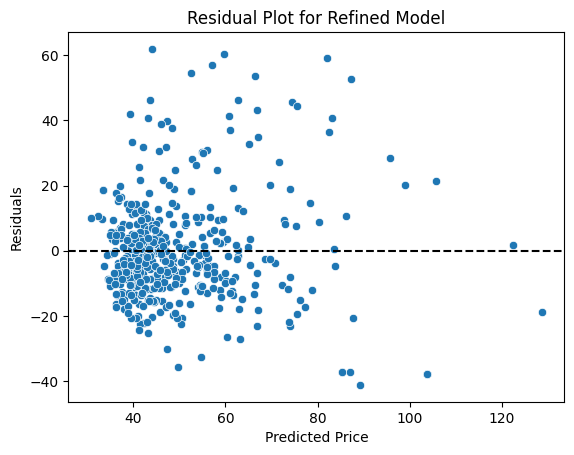

In [21]:
sns.scatterplot(x=refined_model.predict(), y=refined_model.resid)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot for Refined Model");

#### **Notes**

* The residual plot for the refined model does not show a clear curved pattern, so the model meets the linearity assumption.

* Most of the residuals are scattered around 0, which means the model's predictions are fairly balanced.

* The residuals are more spread out for higher predicted prices, which means the model has larger errors for some higher-priced resorts.

* Overall, the refined model meets the linearity assumption, but the wider spread in the residuals shows that the model can still be improved.

### **Independence of Errors**

In [22]:
refined_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.434
Model:                            OLS   Adj. R-squared:                  0.429
Method:                 Least Squares   F-statistic:                     92.95
Date:                Wed, 19 Aug 2026   Prob (F-statistic):           1.25e-58
Time:                        07:21:11   Log-Likelihood:                -2044.3
No. Observations:                 490   AIC:                             4099.
Df Residuals:                     485   BIC:                             4120.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               34.2378      2.191     15.630      0.000      29.934      38.542
Difficult slopes     0.6717      0.046     14.656      0.000       0.582       0.762
Highest point        0.0036      0.001      3.292      0.001       0.001       0.006
Longest run          0.5544      0.188      2.944      0.003       0.184       0.925
Total lifts         -0.2141      0.030     -7.115      0.000      -0.273      -0.155
==============================================================================
Omnibus:                       95.010   Durbin-Watson:                   1.736
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              211.873
Skew:                           1.017   Prob(JB):                     9.83e-47
Kurtosis:                       5.498   Cond. No.                     7.06e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.06e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

### **Notes**

* The Durbin-Watson value for the refined model is 1.736, which falls within the acceptable range of about 1.5 to 2.5 and shows that the independence of errors assumption is met.

* This means the residuals are not strongly related to each other, so the model's errors are not showing a major correlation problem.

* This result makes sense because each row represents a separate ski resort, not time-based data where errors are more likely to be connected.

### **Normality of Errors**

#### **Original Price Model**

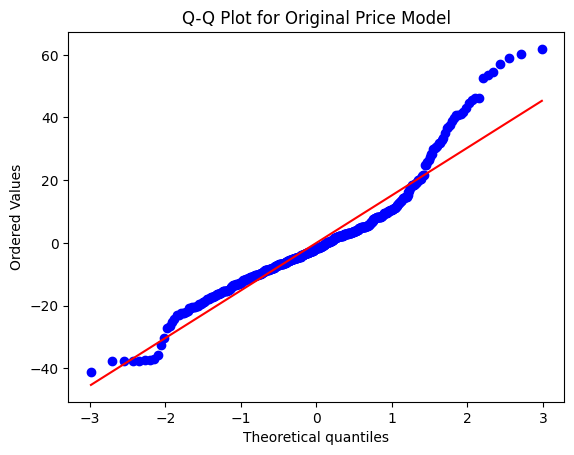

In [23]:

stats.probplot(refined_model.resid, dist="norm", plot=plt)
plt.title("Q-Q Plot for Original Price Model");

#### **Notes**

* The Q-Q plot for the original price model follows the red line in the middle, which means the residuals are close to normal for many predictions.

* The points move away from the red line at both ends, which means the residuals are not perfectly normally distributed.

* The upper-right side moves far above the red line, which means the model has some larger positive errors than expected.

* Since the residuals do not fully follow a normal pattern, the normality of errors assumption is not fully met.

* A log transformation of `Price` will be tested to see if it improves the shape of the residuals.

#### **Log Price Model**

Log Price Model
MAE: 11.192434989331812
RMSE: 16.81180116640703


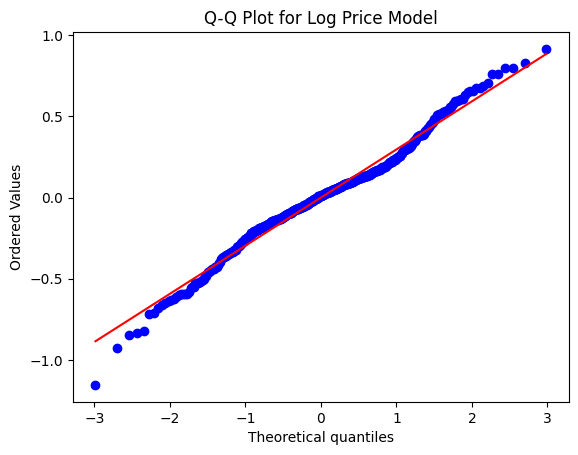

In [24]:
X = sm.add_constant(
    resorts_df[[
        "Difficult slopes",
        "Highest point",
        "Longest run",
        "Total lifts"
    ]]
)

y_log = np.log(resorts_df["Price"]).rename("Log Price")

log_model = sm.OLS(y_log, X).fit()

log_predictions = log_model.predict()
price_predictions = np.exp(log_predictions)

actual_price = resorts_df["Price"]

print("Log Price Model")
print(f"MAE: {mae(actual_price, price_predictions)}")
print(f"RMSE: {rmse(actual_price, price_predictions)}")

stats.probplot(log_model.resid, dist="norm", plot=plt)
plt.title("Q-Q Plot for Log Price Model");

In [25]:
log_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:              Log Price   R-squared:                       0.394
Model:                            OLS   Adj. R-squared:                  0.389
Method:                 Least Squares   F-statistic:                     78.73
Date:                Wed, 19 Aug 2026   Prob (F-statistic):           1.93e-51
Time:                        07:21:11   Log-Likelihood:                -100.89
No. Observations:                 490   AIC:                             211.8
Df Residuals:                     485   BIC:                             232.8
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                3.5357      0.042     85.195      0.000       3.454       3.617
Difficult slopes     0.0109      0.001     12.577      0.000       0.009       0.013
Highest point     5.612e-05   2.05e-05      2.741      0.006    1.59e-05    9.63e-05
Longest run          0.0160      0.004      4.490      0.000       0.009       0.023
Total lifts         -0.0026      0.001     -4.542      0.000      -0.004      -0.001
==============================================================================
Omnibus:                       10.692   Durbin-Watson:                   1.805
Prob(Omnibus):                  0.005   Jarque-Bera (JB):               18.156
Skew:                          -0.085   Prob(JB):                     0.000114
Kurtosis:                       3.928   Cond. No.                     7.06e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 7.06e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

#### **Notes**

* The Q-Q plot for the log price model follows the red line much more closely than the original price model, which means the residuals are more normally distributed.

* Most of the points stay close to the red line, showing that the log transformation improved the shape of the residuals.

* There are still a few points that move away from the line at the ends, which means the residuals are not perfectly normal.

* Overall, the log price model does a better job of meeting the normality of errors assumption than the original price model.

#### **Decision**

* The log price model had a higher MAE and RMSE after predictions were converted back to euros.

* The log price model is harder to explain because its coefficients represent percentage changes rather than euro changes.

* The refined model will be used as the main model because its predictions were more accurate and easier to explain.

* The log model helped with normality, but the refined model still did a better job predicting ski pass prices.

### **No Perfect Multicollinearity**

In [26]:
X = sm.add_constant(
    resorts_df[[
        "Difficult slopes",
        "Highest point",
        "Longest run",
        "Total lifts"
    ]]
)

vif_df = pd.Series(
    [vif(X.values, i) for i in range(X.shape[1])],
    index=X.columns
)

vif_df

,0
const,9.451303
Difficult slopes,1.695966
Highest point,1.382535
Longest run,1.094149
Total lifts,1.380563


### **Notes**

* VIF was used to check whether the predictors in the model overlap too much with each other.

* The `const` value can be ignored because it represents the intercept, not an actual predictor.

* All predictor VIF values are below 5, which means the model does not have a major multicollinearity problem.

* `Difficult slopes` has the highest predictor VIF at about 1.70, but this is still low and not a concern.

* Since the VIF values are low, the model meets the no perfect multicollinearity assumption.

### **Equal Variance of Errors**

##### **Original Price Model**

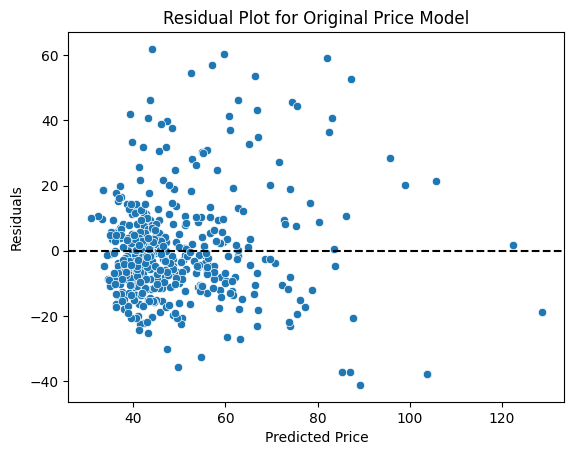

In [27]:
sns.scatterplot(x=refined_model.predict(), y=refined_model.resid)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residuals")
plt.title("Residual Plot for Original Price Model");

##### **Log Price Model**

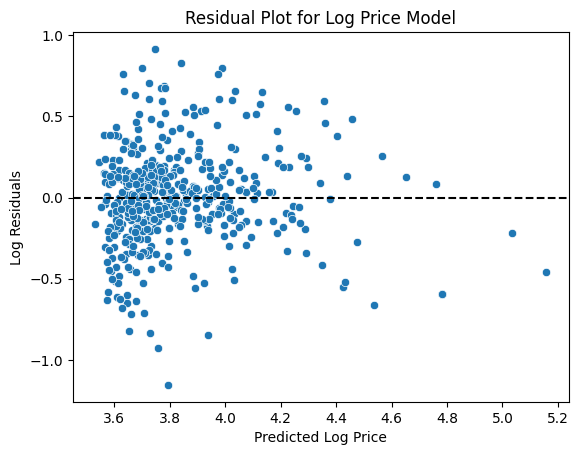

In [28]:
sns.scatterplot(x=log_model.predict(), y=log_model.resid)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Predicted Log Price")
plt.ylabel("Log Residuals")
plt.title("Residual Plot for Log Price Model");

#### **Notes**

* In the original price model, the residuals become more spread out as the predicted price increases, which shows that the equal variance of errors assumption is not fully met.

* The log price model makes the residuals look a little more balanced, but they are still not spread out evenly.

* Since the log model has higher MAE and RMSE after predictions were converted back to euros, the refined model will be kept as the main model.

* Equal variance of errors is a limitation of the refined model, but the model is still useful for prediction.

### **Outliers, Leverage & Influence**

In [29]:
influence = refined_model.get_influence()
inf_summary_df = influence.summary_frame()
inf_summary_df.head()

,dfb_const,dfb_Difficult slopes,dfb_Highest point,dfb_Longest run,dfb_Total lifts,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
ID,,,,,,,,,,,
1,0.014992,-0.004951,-0.013092,0.013512,0.003649,0.000119,0.323393,0.005674,0.024429,0.323095,0.024406
2,0.028239,-0.003088,-0.021533,-0.000888,0.007448,0.000218,0.439590,0.005603,0.032998,0.439224,0.032971
3,0.001164,-0.006739,0.000179,0.012859,-0.000804,0.000058,0.187725,0.008142,0.017009,0.187539,0.016992
4,-0.054041,-0.125492,0.059539,-0.038618,0.085867,0.004300,-1.110937,0.017121,-0.146625,-1.111206,-0.146661
5,0.022667,-0.000350,-0.021797,0.015093,0.001914,0.000174,0.314462,0.008725,0.029502,0.314169,0.029475


In [30]:
inf_summary_df["cooks_d"].sort_values(ascending=False).round(2)

,cooks_d
ID,
145,0.05
143,0.05
146,0.05
140,0.05
98,0.05
...,...
151,0.00
43,0.00
372,0.00


### **Notes**

* Cook's Distance was used to check whether any individual resorts had too much influence on the model.

* The highest Cook's D values were around 0.05, which is far below the warning levels of 0.5 and 1.0.
* Since no major influential outliers were found, no rows need to be removed for this assumption.

## **7. Model Testing and Validation**

### **Model Evaluation Helper Functions**

These helper functions reduce repeated code when checking model performance.

In [31]:
def cross_validate_ols(X_train, y_train, model_name, n_splits=5):
    """Run 5-fold cross-validation for an OLS regression model."""

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=2026)

    cv_r2s = []
    cv_maes = []

    for train_ind, val_ind in kf.split(X_train, y_train):
        X_cv_train, X_cv_val = X_train.iloc[train_ind], X_train.iloc[val_ind]
        y_cv_train, y_cv_val = y_train.iloc[train_ind], y_train.iloc[val_ind]

        cv_model = sm.OLS(y_cv_train, X_cv_train).fit()
        val_predictions = cv_model.predict(X_cv_val)

        cv_r2s.append(r2(y_cv_val, val_predictions))
        cv_maes.append(mae(y_cv_val, val_predictions))

    print("All Validation R2s:", [round(x, 3) for x in cv_r2s])
    print(f"Cross Val R2: {round(np.mean(cv_r2s), 3)} +- {round(np.std(cv_r2s), 3)}")

    print("All Validation MAEs:", [round(x, 3) for x in cv_maes])
    print(f"Cross Val MAE: {round(np.mean(cv_maes), 3)} +- {round(np.std(cv_maes), 3)}")

    return {
        "Model": model_name,
        "Cross Val R2": np.mean(cv_r2s),
        "Cross Val MAE": np.mean(cv_maes),
        "All Validation R2s": cv_r2s,
        "All Validation MAEs": cv_maes
    }


def regression_metrics(model_name, y_true, predictions):
    """Return R-squared, MAE, and RMSE for a regression model."""

    return {
        "Model": model_name,
        "Test R2": r2(y_true, predictions),
        "Test MAE": mae(y_true, predictions),
        "Test RMSE": rmse(y_true, predictions)
    }


def print_regression_metrics(y_true, predictions, label="Test"):
    """Print R-squared, MAE, and RMSE for model predictions."""

    print(f"{label} R2: {round(r2(y_true, predictions), 3)}")
    print(f"{label} MAE: {round(mae(y_true, predictions), 3)}")
    print(f"{label} RMSE: {round(rmse(y_true, predictions), 3)}")



In [32]:
features = ["Difficult slopes", "Highest point", "Longest run", "Total lifts"]

X = sm.add_constant(resorts_df[features])
y = resorts_df["Price"]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2026
)

### **Notes**

* The refined model features were used for model testing and validation.

* The data was split into training and testing sets so the model could be tested on data it had not seen before.

* 80% of the data was used for training, and 20% was used for testing.

* `random_state=2026` was used so the split can be repeated and give the same results each time.

In [33]:
refined_cv_results = cross_validate_ols(
    X_train,
    y_train,
    "Refined Model"
)

All Validation R2s: [0.373, 0.503, 0.569, 0.505, 0.286]
Cross Val R2: 0.447 +- 0.103
All Validation MAEs: [12.275, 9.315, 9.245, 12.633, 12.415]
Cross Val MAE: 11.177 +- 1.553


### **Notes**

* 5-fold cross-validation was used to test how well the refined model performs on different parts of the training data.

* Each fold trains the model on one part of the data and validates it on another part, which gives a more reliable view of performance than using only one split.

* The average cross-validation R-squared was 0.447, which means that the model explained about 44.7% of the price differences in the validation data.
The average cross-validation MAE was about €11.18, meaning the model's predictions were off by about €11 on average.

* The validation R-squared scores ranged from 0.286 to 0.569, which shows that the model performed better on some folds than others.

* Overall, the refined model has moderate predictive power, but there is still room to improve the model with feature engineering.

In [34]:
# Fit the refined model on the training data
test_model = sm.OLS(y_train, X_train).fit()

# Make predictions on the test data
test_predictions = test_model.predict(X_test)

print_regression_metrics(y_test, test_predictions)

Test R2: 0.23
Test MAE: 11.58
Test RMSE: 16.189


### **Notes**

* The refined model was trained on the training data and evaluated on the test data, which was not used during training.

* The test R-squared was 0.230, which means that the model explained about 23% of the price differences in the test data.

* The test MAE was about €11.58, which means that the model's predictions were off by about €11.60 on average.

* The test MAE was close to the cross-validation MAE, but the test R-squared was lower than the cross-validation R-squared.

* The test RMSE was higher than the MAE, which shows that the model had some larger prediction errors.

* Overall, the refined model has some predictive value, but its performance on the test data shows that there is still room to improve with feature engineering.

## **8. Feature Engineering**

### **Combining Features**

* Some features may become more useful when they are combined with other features.

* For example, the difference between the highest and lowest point of a resort may tell us more about the resort than looking at the highest point alone.

* For this project, new combined features were created to capture resort size, terrain difficulty, and lift infrastructure better.

#### **Vertical Drop**

In [35]:
engineered_df = resorts_df.copy()

engineered_df["Vertical drop"] = (
    engineered_df["Highest point"] - engineered_df["Lowest point"]
)

engineered_df[["Highest point", "Lowest point", "Vertical drop"]].head()

,Highest point,Lowest point,Vertical drop
ID,,,
1,1450,620,830
2,1178,800,378
3,2110,650,1460
4,2075,1185,890
5,1030,195,835


#### **Notes**

* A copy of the cleaned dataset was created so that the original dataset remains unchanged.

* The feature `Vertical drop` was created by subtracting `Lowest point` from `Highest point`, which represents the elevation difference at each resort.

* `Vertical drop` may be useful because it gives a clearer picture of resort size and terrain than `Highest point` by itself.

#### **Difficult Slope Percentage**

In [36]:
engineered_df["Difficult slope percentage"] = (
    engineered_df["Difficult slopes"] / engineered_df["Total slopes"]
)

engineered_df[[
    "Difficult slopes",
    "Total slopes",
    "Difficult slope percentage"
]].head()

,Difficult slopes,Total slopes,Difficult slope percentage
ID,,,
1,4,43,0.093023
2,4,34,0.117647
3,1,26,0.038462
4,50,120,0.416667
5,4,44,0.090909


#### **Notes**

* `Difficult slope percentage` was created by dividing `Difficult slopes` by `Total slopes`, which shows what percentage of each resort's slopes are difficult.

* This feature is useful because it shows how much of a resort is made up of advanced terrain.

* This gives more context than `Difficult slopes` by itself because it compares difficult slopes to the resort's total amount of slopes.

#### **Lift Capacity per Lift**

In [37]:
engineered_df["Lift capacity per lift"] = (
    engineered_df["Lift capacity"] / engineered_df["Total lifts"]
)

engineered_df[[
    "Lift capacity",
    "Total lifts",
    "Lift capacity per lift"
]].head()

,Lift capacity,Total lifts,Lift capacity per lift
ID,,,
1,22921,21,1091.476190
2,14225,24,592.708333
3,16240,11,1476.363636
4,9200,8,1150.000000
5,21060,18,1170.000000


#### **Notes**

* `Lift capacity per lift` was created by dividing `Lift capacity` by `Total lifts`,  which shows how many people each lift can carry on average.

* This is useful because two resorts can have the same number of lifts, but one resort may be able to move more people.

* This feature gives a better idea of how strong the resort's lift system is.

#### **Feature-Engineered Model Setup**

In [38]:
print("Total slopes equal to 0:", (engineered_df["Total slopes"] == 0).sum())
print("Total lifts equal to 0:", (engineered_df["Total lifts"] == 0).sum())

Total slopes equal to 0: 0
Total lifts equal to 0: 1


In [39]:
features_engineered = [
    "Vertical drop",
    "Difficult slope percentage",
    "Longest run",
    "Lift capacity per lift"
]

engineered_model_df = engineered_df[engineered_df["Total lifts"] != 0].copy()

X_engineered = sm.add_constant(engineered_model_df[features_engineered])
y_engineered = engineered_model_df["Price"]

X_eng_train, X_eng_test, y_eng_train, y_eng_test = train_test_split(
    X_engineered,
    y_engineered,
    test_size=0.2,
    random_state=2026
)

#### **Notes**

* The two new division-based features were checked for possible division issues.

* `Total slopes` did not have any zero values, so `Difficult slope percentage` did not create a division problem.

* `Total lifts` had one zero value, which affected `Lift capacity per lift`, so that row was removed from the feature-engineered model dataset.

#### **Cross-Validation for Feature-Engineered Model**

In [40]:
engineered_cv_results = cross_validate_ols(
    X_eng_train,
    y_eng_train,
    "Feature-Engineered Model"
)

All Validation R2s: [0.382, 0.373, 0.338, 0.332, 0.189]
Cross Val R2: 0.323 +- 0.07
All Validation MAEs: [12.248, 11.769, 11.894, 12.154, 11.636]
Cross Val MAE: 11.94 +- 0.23


#### **Notes**

* 5-fold cross-validation was used to test how well the feature-engineered model performed on different parts of the training data.

* The average cross-validation R-squared was 0.323, meaning the model explained about 32.3% of the price differences in the validation data.

* The average cross-validation MAE was about €11.94, meaning the model's predictions were off by about €12 on average.

* Compared to the refined model, the feature-engineered model performed worse because its R-squared was lower and its MAE was higher.

### **Interaction Terms**

#### **Difficult Slopes and North America Interaction**

* The lmplot from the EDA section showed that the relationship between `Difficult slopes` and `Price` looked different across continents.

* North America showed one of the strongest relationships, so an interaction between `Difficult slopes` and a North America flag will be tested.

* The goal is to see whether difficult slopes affect ski pass prices differently for North American resorts compared to resorts in other continents.

In [41]:
interaction_df = resorts_df.copy()

interaction_df = interaction_df.assign(
    north_america_flag = np.where(interaction_df["Continent"] == "North America", 1, 0),
    difficult_slopes_north_america_int = lambda x: x["Difficult slopes"] * x["north_america_flag"]
)

interaction_features = [
    "Difficult slopes",
    "Highest point",
    "Longest run",
    "Total lifts",
    "north_america_flag",
    "difficult_slopes_north_america_int"
]

X_interaction = sm.add_constant(interaction_df[interaction_features])
y_interaction = interaction_df["Price"]

X_int_train, X_int_test, y_int_train, y_int_test = train_test_split(
    X_interaction,
    y_interaction,
    test_size=0.2,
    random_state=2026
)

#### **Cross-Validation for Interaction Model**

In [42]:
interaction_cv_results = cross_validate_ols(
    X_int_train,
    y_int_train,
    "Interaction Model"
)

All Validation R2s: [0.588, 0.637, 0.722, 0.712, 0.515]
Cross Val R2: 0.635 +- 0.077
All Validation MAEs: [10.146, 8.223, 7.248, 9.386, 9.822]
Cross Val MAE: 8.965 +- 1.078


#### **Notes**

* 5-fold cross-validation was used to test how well the interaction model performed on different parts of the training data.

* The average cross-validation R-squared was 0.635, meaning the model explained about 63.5% of the price differences in the validation data.

* The average cross-validation MAE was about €8.97, meaning the model’s predictions were off by about €9 on average.

* Compared to the refined model, the interaction model performed much better because its R-squared was higher and its MAE was lower.

* This suggests that North American resorts may price difficult terrain differently than resorts in other continents.

#### **Test Set Evaluation for Interaction Model**

In [43]:
# Fit the interaction model on the training data
interaction_model = sm.OLS(y_int_train, X_int_train).fit()

# Make predictions on the test data
interaction_test_predictions = interaction_model.predict(X_int_test)

print_regression_metrics(y_int_test, interaction_test_predictions)

interaction_model.summary()

Test R2: 0.501
Test MAE: 10.172
Test RMSE: 13.028


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.649
Model:                            OLS   Adj. R-squared:                  0.644
Method:                 Least Squares   F-statistic:                     118.9
Date:                Wed, 19 Aug 2026   Prob (F-statistic):           1.82e-84
Time:                        07:21:13   Log-Likelihood:                -1550.3
No. Observations:                 392   AIC:                             3115.
Df Residuals:                     385   BIC:                             3142.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
======================================================================================================
                                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------
const                                 27.5239      2.061     13.354      0.000      23.472      31.576
Difficult slopes                       0.0621      0.071      0.869      0.385      -0.078       0.202
Highest point                          0.0044      0.001      4.518      0.000       0.002       0.006
Longest run                            0.7736      0.169      4.571      0.000       0.441       1.106
Total lifts                            0.0928      0.036      2.583      0.010       0.022       0.163
north_america_flag                    21.3036      2.757      7.726      0.000      15.882      26.725
difficult_slopes_north_america_int     0.3885      0.089      4.350      0.000       0.213       0.564
==============================================================================
Omnibus:                       42.557   Durbin-Watson:                   1.867
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              102.514
Skew:                           0.548   Prob(JB):                     5.49e-23
Kurtosis:                       5.253   Cond. No.                     1.02e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.02e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

#### **Notes**

* The interaction model was trained on the training data and evaluated on the test data, which was not used during training.

* The test R-squared was 0.501, meaning the model explained about 50.1% of the price differences in the test data.

* The test MAE was about €10.17, meaning the model’s predictions were off by about €10 on average.

* Compared to the refined model, the interaction model performed better on the test data because it had a higher R-squared and lower MAE and RMSE.

* The `north_america_flag` and `difficult_slopes_north_america_int` variables were statistically significant, which suggests that North American resorts price difficult terrain differently than resorts in other continents.

* The condition number was large, so multicollinearity or scaling should be checked before choosing this as the final model.

#### **Multicollinearity Check for Interaction Model**

In [44]:
vif_df = pd.Series(
    [vif(X_int_train.values, i) for i in range(X_int_train.shape[1])],
    index=X_int_train.columns
)

vif_df

,0
const,10.253854
Difficult slopes,5.070547
Highest point,1.395904
Longest run,1.096230
Total lifts,2.679455
north_america_flag,2.981010
difficult_slopes_north_america_int,5.704346


#### **Notes**

* VIF was used to check whether the predictors in the interaction model overlap too much with each other.

* Most predictor VIF values were below 5, so most features did not show a major multicollinearity problem.

* `Difficult slopes` and `difficult_slopes_north_america_int` were slightly above 5, which is expected because the interaction term was created from `Difficult slopes`.

* Since the VIF values were only slightly above 5 and the interaction model performed better, the model will be kept for now.

### **Categorical Features**

#### **Binning Season**

In [45]:
categorical_df = resorts_df.copy()

common_seasons = [
    "December - April",
    "November - April",
    "December - March",
    "November - May",
    "Unknown"
]

categorical_df["Season binned"] = np.where(
    categorical_df["Season"].isin(common_seasons),
    categorical_df["Season"],
    "Other"
)

categorical_df["Season binned"].value_counts()

,count
Season binned,
December - April,217
November - April,107
Other,66
December - March,40
November - May,35
Unknown,25


#### **Notes**

* `Season` had a lot of small categories, so it was simplified before being used in the model.

* The most common season values were kept as their own groups.

* Less common season values were grouped into `Other` so the model would not create too many extra columns.

* The cleaned `Season binned` feature will be used when creating dummy variables.

#### **Dummy Variables**

In [46]:
categorical_columns = [
    "Continent",
    "Snowparks",
    "Nightskiing",
    "Season binned"
]

categorical_dummies = pd.get_dummies(
    categorical_df[categorical_columns],
    drop_first=True,
    dtype=int
)

categorical_dummies.head()

,Continent_Europe,Continent_North America,Continent_Oceania,Continent_South America,Snowparks_Yes,Nightskiing_Yes,Season binned_December - March,Season binned_November - April,Season binned_November - May,Season binned_Other,Season binned_Unknown
ID,,,,,,,,,,,
1,1,0,0,0,1,1,0,0,1,0,0
2,1,0,0,0,1,1,0,1,0,0,0
3,1,0,0,0,0,0,0,0,0,0,0
4,0,1,0,0,1,1,0,0,0,0,0
5,1,0,0,0,1,1,0,1,0,0,0


#### **Notes**

* Dummy variables were created because regression models are not able to use text categories directly, so the categories needed to be changed into numbers.

* `drop_first=True` was used because one category from each feature needs to be left out to avoid repeating the same information.

* These dummy variables will be added to the model to see if categorical features make the predictions better.

#### **Categorical Model Setup**

In [47]:
categorical_model_df = pd.concat(
    [
        categorical_df[[
            "Price",
            "Difficult slopes",
            "Highest point",
            "Longest run",
            "Total lifts"
        ]],
        categorical_dummies
    ],
    axis=1
)

categorical_model_df.head()

,Price,Difficult slopes,Highest point,Longest run,Total lifts,Continent_Europe,Continent_North America,Continent_Oceania,Continent_South America,Snowparks_Yes,Nightskiing_Yes,Season binned_December - March,Season binned_November - April,Season binned_November - May,Season binned_Other,Season binned_Unknown
ID,,,,,,,,,,,,,,,,
1,46,4,1450,6,21,1,0,0,0,1,1,0,0,1,0,0
2,44,4,1178,2,24,1,0,0,0,1,1,0,1,0,0,0
3,48,1,2110,9,11,1,0,0,0,0,0,0,0,0,0,0
4,60,50,2075,7,8,0,1,0,0,1,1,0,0,0,0,0
5,45,4,1030,6,18,1,0,0,0,1,1,0,1,0,0,0


In [48]:
X_categorical = sm.add_constant(
    categorical_model_df.drop(columns="Price")
)

y_categorical = categorical_model_df["Price"]

X_cat_train, X_cat_test, y_cat_train, y_cat_test = train_test_split(
    X_categorical,
    y_categorical,
    test_size=0.2,
    random_state=2026
)

In [49]:
categorical_cv_results = cross_validate_ols(
    X_cat_train,
    y_cat_train,
    "Categorical Model"
)

All Validation R2s: [0.619, 0.723, 0.743, 0.689, 0.614]
Cross Val R2: 0.678 +- 0.053
All Validation MAEs: [9.856, 7.675, 7.222, 9.547, 9.13]
Cross Val MAE: 8.686 +- 1.046


#### **Notes**

* The categorical model had an average cross-validation R-squared of 0.678, which means that it explained about 67.8% of the price differences in the validation data.

* The average cross-validation MAE was about €8.69, meaning the model’s predictions were off by about €9 on average.

* This model performed better than the refined model because it had a higher R-squared and a lower MAE.

* This model also performed slightly better than the interaction model in cross-validation, which suggests that the categorical features added useful pricing information.

#### **Test Set Evaluation for Categorical Model**

In [50]:
# Fit the categorical model on the training data
categorical_model = sm.OLS(y_cat_train, X_cat_train).fit()

# Make predictions on the test data
categorical_test_predictions = categorical_model.predict(X_cat_test)

print_regression_metrics(y_cat_test, categorical_test_predictions)

categorical_model.summary()

Test R2: 0.559
Test MAE: 9.423
Test RMSE: 12.25


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  Price   R-squared:                       0.704
Model:                            OLS   Adj. R-squared:                  0.692
Method:                 Least Squares   F-statistic:                     59.49
Date:                Wed, 19 Aug 2026   Prob (F-statistic):           2.01e-89
Time:                        07:21:13   Log-Likelihood:                -1517.5
No. Observations:                 392   AIC:                             3067.
Df Residuals:                     376   BIC:                             3131.
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
==================================================================================================
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const                             23.8492      3.978      5.995      0.000      16.027      31.671
Difficult slopes                   0.2394      0.049      4.841      0.000       0.142       0.337
Highest point                      0.0039      0.001      4.113      0.000       0.002       0.006
Longest run                        0.7911      0.168      4.723      0.000       0.462       1.120
Total lifts                        0.0402      0.030      1.327      0.185      -0.019       0.100
Continent_Europe                   0.0068      3.209      0.002      0.998      -6.302       6.316
Continent_North America           27.5488      3.626      7.597      0.000      20.418      34.679
Continent_Oceania                 34.3456      6.005      5.719      0.000      22.538      46.153
Continent_South America            4.8395      6.050      0.800      0.424      -7.056      16.735
Snowparks_Yes                      2.1185      1.693      1.252      0.211      -1.210       5.447
Nightskiing_Yes                   -1.9491      1.327     -1.469      0.143      -4.558       0.660
Season binned_December - March     1.9615      2.455      0.799      0.425      -2.866       6.789
Season binned_November - April     8.4890      1.691      5.021      0.000       5.164      11.814
Season binned_November - May       2.2775      2.389      0.953      0.341      -2.419       6.974
Season binned_Other                4.8982      2.246      2.181      0.030       0.482       9.314
Season binned_Unknown              1.3912      3.119      0.446      0.656      -4.742       7.525
==============================================================================
Omnibus:                       29.359   Durbin-Watson:                   1.999
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               92.564
Skew:                           0.243   Prob(JB):                     7.94e-21
Kurtosis:                       5.331   Cond. No.                     3.12e+04
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 3.12e+04. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

#### **Notes**

* The categorical model had a test R-squared of 0.559, meaning it explained about 55.9% of the price differences in the test data.

* The test MAE was about €9.42, and the test RMSE was 12.25, meaning the model was usually off by about €9 but still had some larger errors.

* Compared to the refined model and interaction model, the categorical model performed better on the test data because it had the highest R-squared and the lowest MAE and RMSE.

* The condition number was large, so multicollinearity should be checked before choosing this as the final model.

In [51]:
vif_df = pd.Series(
    [vif(X_cat_train.values, i) for i in range(X_cat_train.shape[1])],
    index=X_cat_train.columns
)

vif_df

,0
const,44.114039
Difficult slopes,2.808992
Highest point,1.549071
Longest run,1.240171
Total lifts,2.192472
Continent_Europe,5.728587
Continent_North America,5.954849
Continent_Oceania,1.515117
Continent_South America,1.537672
Snowparks_Yes,1.321082


#### **Notes**

* VIF was checked because the categorical model had a large condition number.

* Most predictor VIF values were below 5, which means most features do not show a major multicollinearity problem.

* `Continent_Europe` and `Continent_North America` were slightly above 5, but this is not a major concern because they are only a little above the usual warning level.

* The high `const` value can be ignored because it represents the intercept, not an actual feature.

* Overall, multicollinearity is not a major problem, and the slightly higher continent VIF values are only a small limitation of the model.

## **9. Regularized Regression**

Regularized regression will be tested to see whether Ridge or Lasso can improve the categorical model.

### **Standardization**

**Notes**

* The input features from the categorical model will be used for regularized regression because this model performed the best so far.

* The features need to be standardized before being used in Ridge and Lasso so they are on a similar scale, which helps prevent larger-number features from being treated as more important just because their values are bigger.

* The scaler will only learn from the training data and then apply the same scaling rules to the test data.

In [52]:
# Use the categorical model inputs, but remove the const column for sklearn
X_regularized = X_categorical.drop(columns="const")
y_regularized = y_categorical

# Save feature names for later
regularized_features = X_regularized.columns

# Split data into training and testing sets
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_regularized,
    y_regularized,
    test_size=0.2,
    random_state=2026
)

In [53]:
std = StandardScaler()

X_reg_train_scaled = std.fit_transform(X_reg_train.values)
X_reg_test_scaled = std.transform(X_reg_test.values)

In [54]:
pd.DataFrame(X_reg_train_scaled, columns=regularized_features).head()

,Difficult slopes,Highest point,Longest run,Total lifts,Continent_Europe,Continent_North America,Continent_Oceania,Continent_South America,Snowparks_Yes,Nightskiing_Yes,Season binned_December - March,Season binned_November - April,Season binned_November - May,Season binned_Other,Season binned_Unknown
0,4.633152,2.089320,1.088484,-0.153928,-1.621613,1.974842,-0.124676,-0.124676,0.514311,1.160735,-0.287877,1.805788,-0.298142,-0.369096,-0.225695
1,-0.687589,-0.381578,-0.418352,-0.460912,0.616670,-0.506370,-0.124676,-0.124676,0.514311,1.160735,3.473711,-0.553775,-0.298142,-0.369096,-0.225695
2,1.283056,-0.130256,1.088484,-0.460912,-1.621613,1.974842,-0.124676,-0.124676,0.514311,1.160735,-0.287877,1.805788,-0.298142,-0.369096,-0.225695
3,-0.441259,0.377515,0.083927,-0.085709,0.616670,-0.506370,-0.124676,-0.124676,0.514311,-0.861523,-0.287877,-0.553775,-0.298142,-0.369096,-0.225695
4,-0.391992,0.368539,-0.920631,-0.563241,0.616670,-0.506370,-0.124676,-0.124676,0.514311,-0.861523,-0.287877,-0.553775,-0.298142,2.709322,-0.225695


In [55]:
X_reg_train.head()

,Difficult slopes,Highest point,Longest run,Total lifts,Continent_Europe,Continent_North America,Continent_Oceania,Continent_South America,Snowparks_Yes,Nightskiing_Yes,Season binned_December - March,Season binned_November - April,Season binned_November - May,Season binned_Other,Season binned_Unknown
ID,,,,,,,,,,,,,,,
155,111,3813,8,21,0,1,0,0,1,1,0,1,0,0,0
460,3,1886,2,12,1,0,0,0,1,1,1,0,0,0,0
12,43,2082,8,12,0,1,0,0,1,1,0,1,0,0,0
276,8,2478,4,23,1,0,0,0,1,0,0,0,0,0,0
336,9,2471,0,9,1,0,0,0,1,0,0,0,0,1,0


#### **Ridge Regression**

In [56]:
# Generate 200 alpha values between 0.001 and 1000
n_alphas = 200
alphas = 10 ** np.linspace(-3, 3, n_alphas)

# Use cross-validation to choose the best alpha
ridge_model = RidgeCV(
    alphas=alphas,
    cv=5,
    scoring="r2"
)

ridge_model.fit(X_reg_train_scaled, y_reg_train);

In [57]:
ridge_train_predictions = ridge_model.predict(X_reg_train_scaled)

print(f"Train R2: {round(ridge_model.score(X_reg_train_scaled, y_reg_train), 3)}")
print(f"Train MAE: {round(mae(y_reg_train, ridge_train_predictions), 3)}")
print(f"Best Ridge Alpha: {ridge_model.alpha_}")

Train R2: 0.702
Train MAE: 8.329
Best Ridge Alpha: 16.638168860761272


In [58]:
ridge_test_predictions = ridge_model.predict(X_reg_test_scaled)

print_regression_metrics(y_reg_test, ridge_test_predictions)

Test R2: 0.568
Test MAE: 9.287
Test RMSE: 12.131


##### **Notes**

* RidgeCV was used to test different alpha values and choose the best one using cross-validation.

* The best Ridge alpha was about `16.64`.

* The Ridge test R-squared was 0.568, meaning the model explained about 56.8% of the price differences in the test data.

* The test MAE was about €9.29, meaning the model’s predictions were off by about €9 on average.

* The test RMSE was 12.13, which is higher than the MAE because the model still had some larger prediction errors.

* Compared to the categorical model, Ridge performed slightly better because it had a higher test R-squared and lower MAE and RMSE.

#### **Ridge Coefficients**

In [59]:
ridge_coefs = pd.DataFrame({
    "Feature": regularized_features,
    "Coefficient": ridge_model.coef_
})

ridge_coefs

,Feature,Coefficient
0,Difficult slopes,5.012443
1,Highest point,2.985179
2,Longest run,3.096236
3,Total lifts,1.006466
4,Continent_Europe,-1.663815
5,Continent_North America,9.200773
6,Continent_Oceania,3.617421
7,Continent_South America,0.157253
8,Snowparks_Yes,0.876714
9,Nightskiing_Yes,-0.998587


##### **Notes**

* The Ridge coefficients show how each standardized feature is related to ski pass price in the final Ridge model.

* Positive coefficients are related to higher predicted prices, while negative coefficients are related to lower predicted prices.

* Since the features were standardized, the coefficients are mainly useful for comparing direction and relative strength, not exact euro changes.

* For example, `Continent_North America` had one of the strongest positive coefficients, which suggests that North American resorts were strongly associated with higher predicted ski pass prices.

#### **Lasso Regression**

In [60]:
# Generate 200 alpha values between 0.001 and 1000
n_alphas = 200
alphas = 10 ** np.linspace(-3, 3, n_alphas)

# Use cross-validation to choose the best alpha
lasso_model = LassoCV(
    alphas=alphas,
    cv=5
)

lasso_model.fit(X_reg_train_scaled, y_reg_train);

In [61]:
lasso_train_predictions = lasso_model.predict(X_reg_train_scaled)

print(f"Train R2: {round(lasso_model.score(X_reg_train_scaled, y_reg_train), 3)}")
print(f"Train MAE: {round(mae(y_reg_train, lasso_train_predictions), 3)}")
print(f"Best Lasso Alpha: {lasso_model.alpha_}")
print(f"Number of Features Used: {np.sum(lasso_model.coef_ != 0)}")

Train R2: 0.702
Train MAE: 8.313
Best Lasso Alpha: 0.2097046401323233
Number of Features Used: 14


In [62]:
lasso_test_predictions = lasso_model.predict(X_reg_test_scaled)

print(f"Test R2: {round(lasso_model.score(X_reg_test_scaled, y_reg_test), 3)}")
print(f"Test MAE: {round(mae(y_reg_test, lasso_test_predictions), 3)}")
print(f"Test RMSE: {round(rmse(y_reg_test, lasso_test_predictions), 3)}")

Test R2: 0.56
Test MAE: 9.377
Test RMSE: 12.232


##### **Notes**

* LassoCV was used to test different alpha values and choose the best one using cross-validation.

* The best Lasso alpha was about `0.21`.

* The Lasso model had a test R-squared of 0.560, meaning it explained about 56.0% of the price differences in the test data.

* The test MAE was about €9.38, meaning the model’s predictions were off by about €9 on average.

* Lasso used 14 features, which means it removed 1 feature by setting its coefficient to 0.

* Compared to Ridge, Lasso performed slightly worse because it had a lower test R-squared and slightly higher MAE and RMSE.

#### **Lasso Coefficients**

In [63]:
lasso_coefs = pd.DataFrame({
    "Feature": regularized_features,
    "Coefficient": lasso_model.coef_
})

lasso_coefs

,Feature,Coefficient
0,Difficult slopes,5.108763
1,Highest point,2.997767
2,Longest run,2.920723
3,Total lifts,0.705131
4,Continent_Europe,-0.360275
5,Continent_North America,10.467709
6,Continent_Oceania,3.870859
7,Continent_South America,0.311140
8,Snowparks_Yes,0.658758
9,Nightskiing_Yes,-0.643972


##### **Notes**

* The Lasso coefficients show how each standardized feature is related to predicted ski pass price.

* Positive coefficients are related to higher predicted prices, while negative coefficients are related to lower predicted prices.

* `Season binned_Unknown` had a coefficient of 0, which means Lasso removed that feature from the final model.

* Since the features were standardized, the coefficients are mainly useful for comparing direction and relative strength, not exact euro changes.

## **10. Final Model Comparison**

In [64]:
refined_test_results = regression_metrics(
    "Refined Model",
    y_test,
    test_predictions
)

interaction_test_results = regression_metrics(
    "Interaction Model",
    y_int_test,
    interaction_test_predictions
)

categorical_test_results = regression_metrics(
    "Categorical Model",
    y_cat_test,
    categorical_test_predictions
)

ridge_test_results = regression_metrics(
    "Ridge Model",
    y_reg_test,
    ridge_test_predictions
)

lasso_test_results = regression_metrics(
    "Lasso Model",
    y_reg_test,
    lasso_test_predictions
)

model_comparison = pd.DataFrame([
    refined_test_results,
    interaction_test_results,
    categorical_test_results,
    ridge_test_results,
    lasso_test_results
]).round(3)

model_comparison

,Model,Test R2,Test MAE,Test RMSE
0,Refined Model,0.230,11.580,16.189
1,Interaction Model,0.501,10.172,13.028
2,Categorical Model,0.559,9.423,12.250
3,Ridge Model,0.568,9.287,12.131
4,Lasso Model,0.560,9.377,12.232


#### **Notes**

* The Ridge model performed the best overall because it had the highest test R-squared and the lowest test MAE and RMSE.

* The Ridge model explained about 56.8% of the price differences in the test data.

* The Ridge model’s predictions were off by about €9.29 on average.

* Lasso also performed well, but Ridge performed slightly better on the test data.

* Based on these results, the Ridge model will be selected as the final model.

## **11. Conclusion**

* The Ridge model was selected as the final model because it was the one that performed the best on the test data.

* The Ridge model had the highest test R-squared and the lowest test MAE and RMSE compared to the other models tested. It explained about 56.8% of the price differences in the test data, and its predictions were off by about €9.29 on average.

* The results show that ski pass prices are influenced by a combination of resort terrain, location, season, and resort features. Adding categorical features, especially continent and season information, improved the model compared to using only numeric resort features.

* Even though the final model performed better than the earlier models, it still has limitations. The model does not explain all of the price differences, and some prediction errors are still fairly large. This means there are likely other factors affecting ski pass prices that were not included in the dataset.

## **12. Recommendations**

* Based on the final Ridge model, ski resorts should consider terrain, location, season, and resort features when making pricing decisions.

* The model can be a useful starting point for estimating ski pass prices, but it should not be used as the only pricing tool.

* Since the model explained about 56.8% of the price differences in the test data, there are still other factors that likely affect ski pass prices.

* Future improvements could include adding more data, such as snowfall, resort popularity, hotel availability, customer demand, holiday periods, and nearby competition.

* Overall, the model gives a helpful estimate of ski pass prices, but it would be stronger with more business and demand-related data.